In [1]:
import numpy as np
import cv2 
import matplotlib.pyplot as plt

In [20]:
img = cv2.imread("silver-surfer.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
pixels = img.reshape(-1,3)/255


In [21]:
def find_bmu(pixel, weights):
    distances = np.sqrt(np.sum((pixel-weights)**2,axis=2)) # Euclidean distance between the input pixel and each neuron
    bmu = np.unravel_index(np.argmin(distances), distances.shape) # Find the smallest distanced neuron to the pixel from the 3*2 grid of neurons
    return bmu

In [22]:
def train_som(pixels, rows,cols, epochs):
    weights = np.random.rand(rows, cols,3)
    lr = 0.1
    sigma = 1
    for epoch in range(epochs):
        pixel = pixels[np.random.randint(len(pixels))] # Randomly selects one pixel from 10,000
        bmu = find_bmu(pixel, weights)

        for i in range(rows):
            for j in range(cols):
                distance = np.sqrt((i-bmu[0])**2 + (j-bmu[1])**2) #Calculate the distance of the current neuron with BMU
                influence = np.exp(-(distance**2)/2*sigma**2) 
                '''Guassian neighbourhood function for distance = 0(for winner neuron) influence=1(full influence) 
                    for neighbouring neuron distance = 1 ->> influence=0.607 this goes on decreasing as the distance increases so the winner learns 
                    most while neighours learns less'''
                weights[i,j] += lr*influence*(pixel-weights[i,j]) #update the weights to move the winner neuron towards the randomly selected pixel
        return weights

In [23]:
def compress_img(pixels, weights, shape):
    compressed = []
    for pixel in pixels:
        bmu = find_bmu(pixel, weights)
        compressed.append(weights[bmu])
        
    compressed = np.array(compressed)
    compressed = (compressed*255).astype(np.uint8)
    return compressed.reshape(shape)

In [30]:
weights = train_som(pixels, 6, 4, 1000) #Change the number of neurons to get less compressed image 
print("Training completed !")

Training completed !


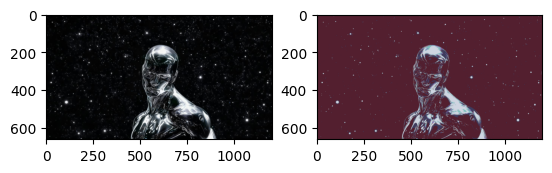

In [31]:
compressed_img = compress_img(pixels, weights, img.shape)

plt.subplot(1,2,1)
plt.imshow(img)

plt.subplot(1,2,2)
plt.imshow(compressed_img)